ORACLE-X | FAILURE DISCOVERY & NETWORK RESILIENCE ENGINE

Architecture: 22 services, 29 dependencies
Telemetry shape: (11000, 8)
Anomaly detection complete: 660 flagged rows

TOP 10 SERVICE RISKS
             service  risk_score risk_level  anomaly_rate
         API_Gateway   56.346460     MEDIUM          0.06
        ML_Inference   45.584943     MEDIUM          0.06
Notification_Service   43.910944     MEDIUM          0.06
        User_Service   43.842644     MEDIUM          0.06
  Monitoring_Service   40.827620     MEDIUM          0.06
          Primary_DB   40.008678     MEDIUM          0.06
       Queue_Service   39.239217     MEDIUM          0.06
        Auth_Service   36.935144     MEDIUM          0.06
     Payment_Service   35.291640     MEDIUM          0.06
        Web_Frontend   34.781335        LOW          0.06

[5/10] Simulating cascading failures...

SIMULATED STRATEGY COMPARISON
  strategy  mean_failed_services  cascade_probability  maximum_failed_services  change_vs_base

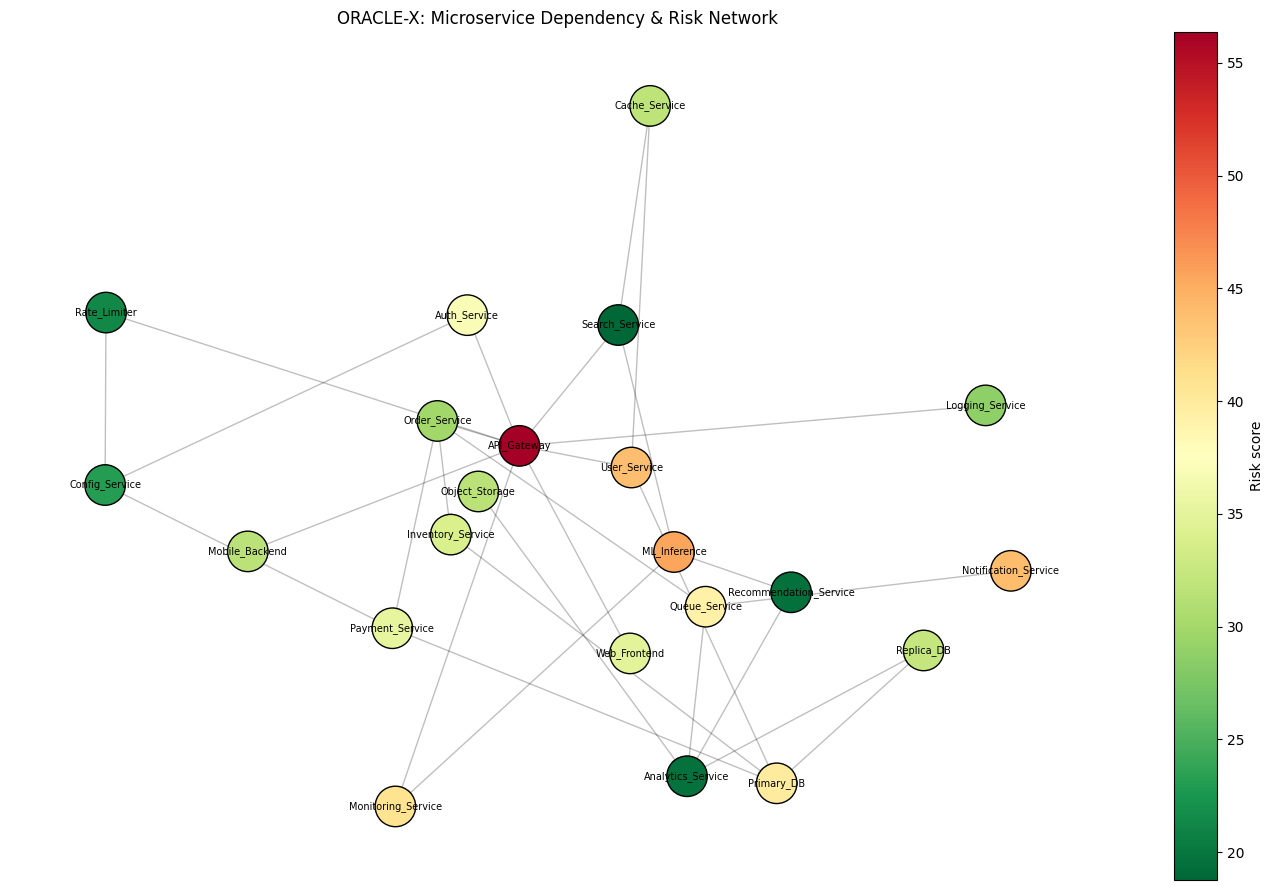

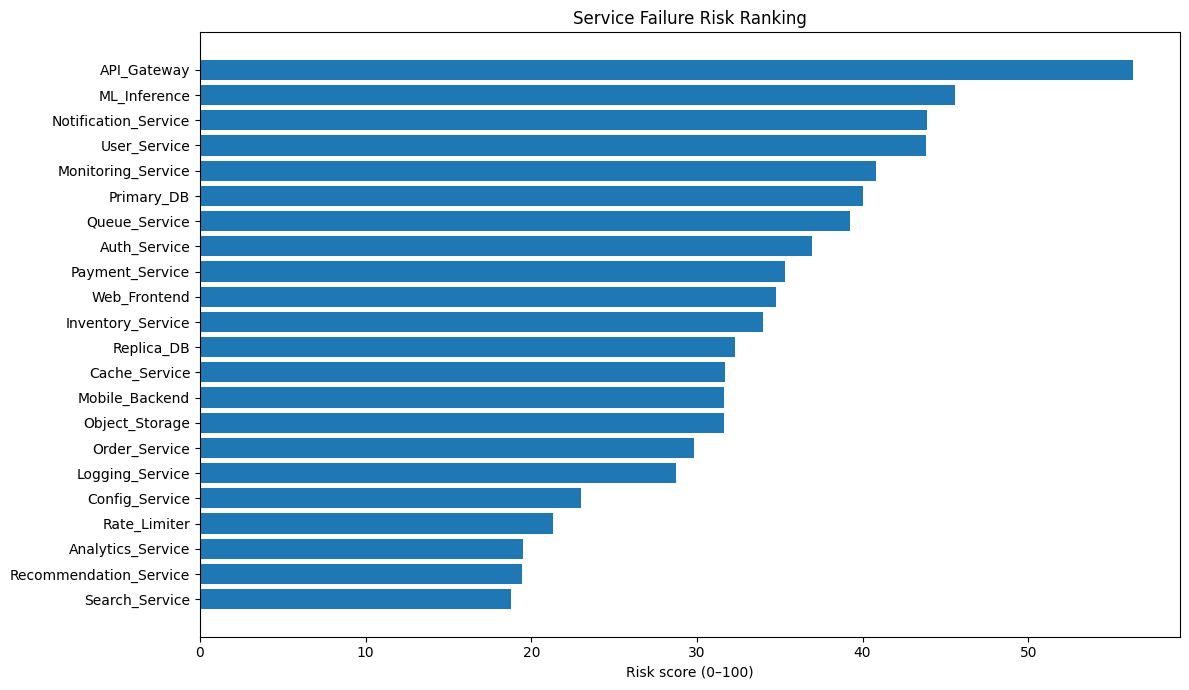

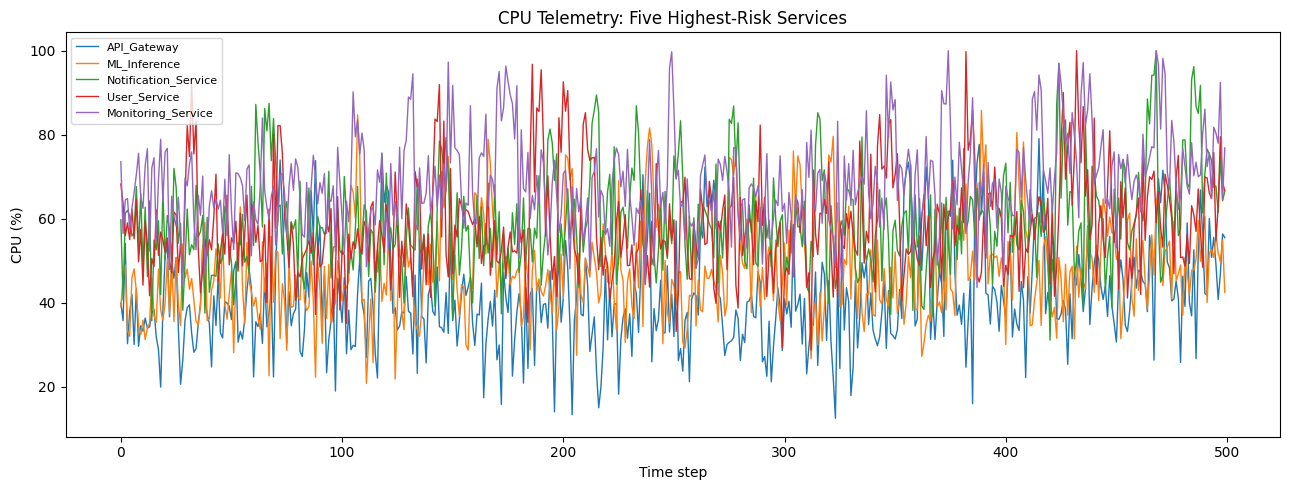

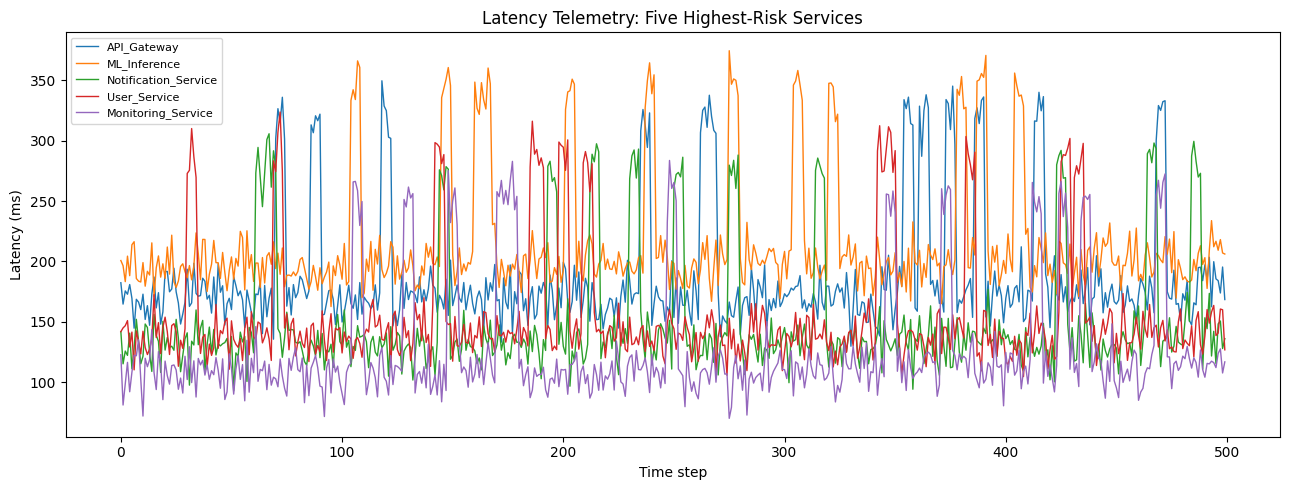

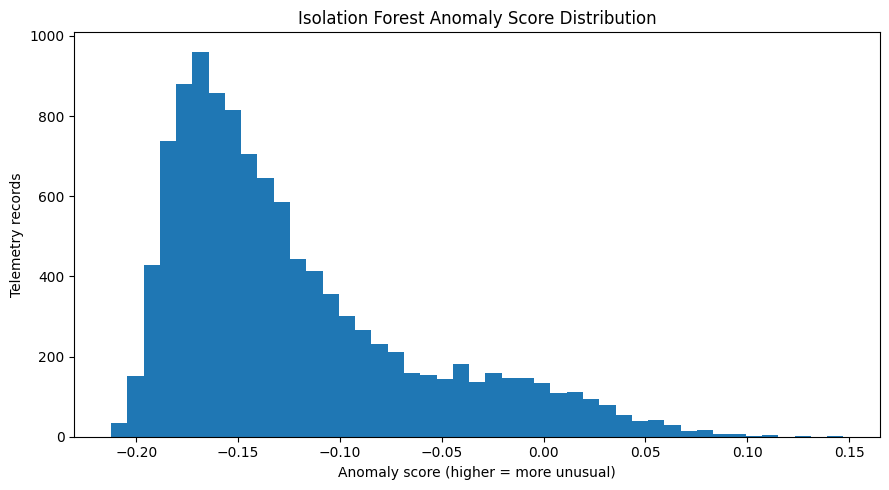

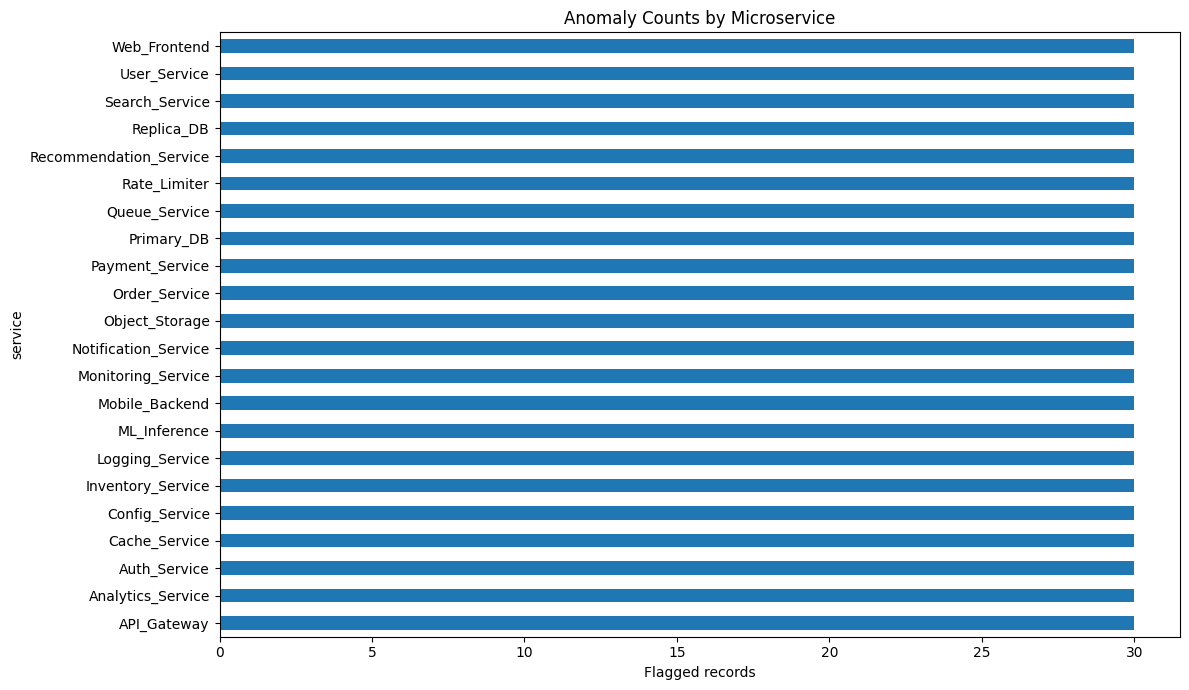

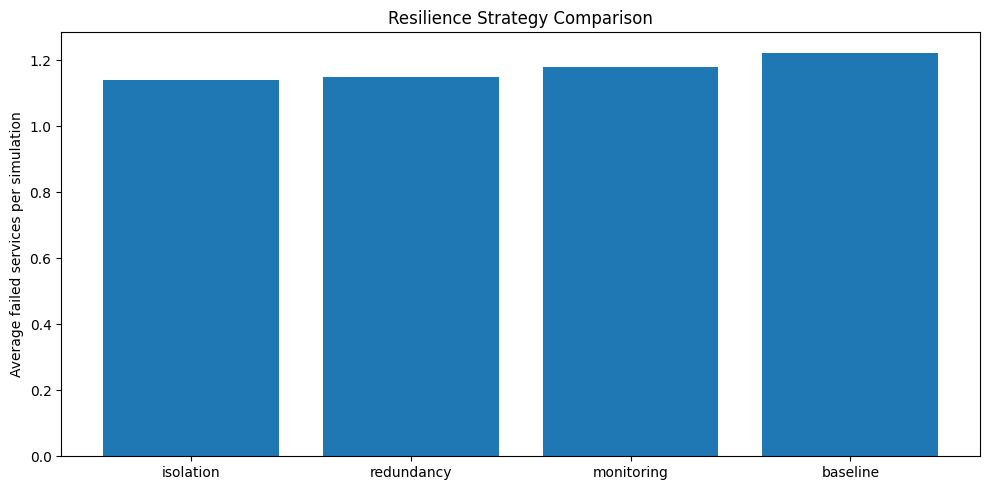

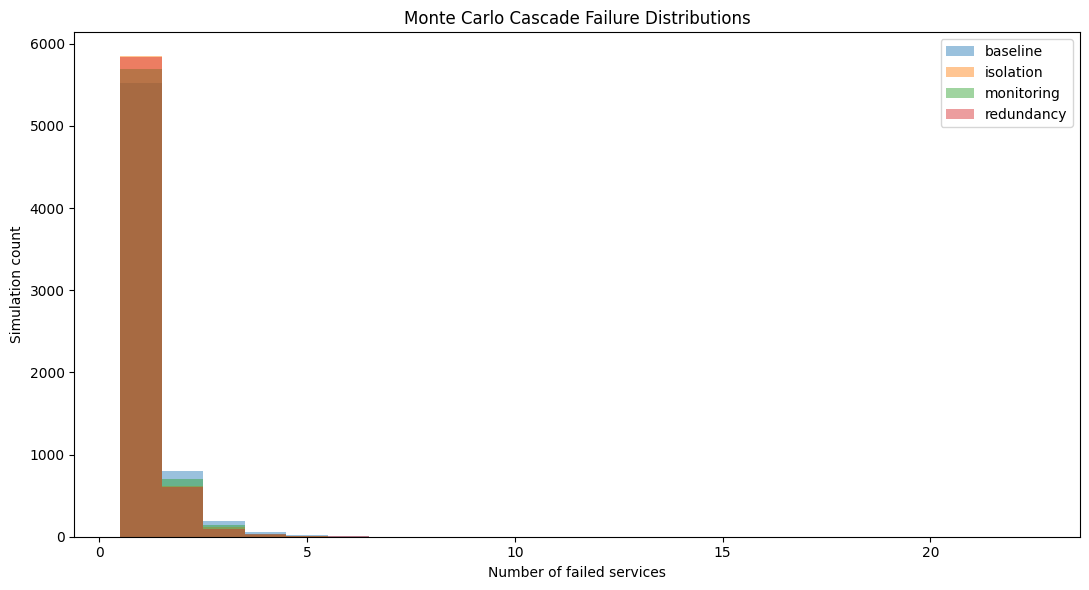

<Figure size 600x500 with 0 Axes>

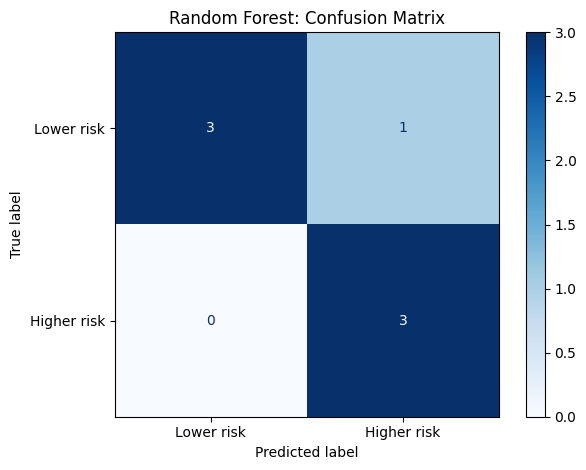

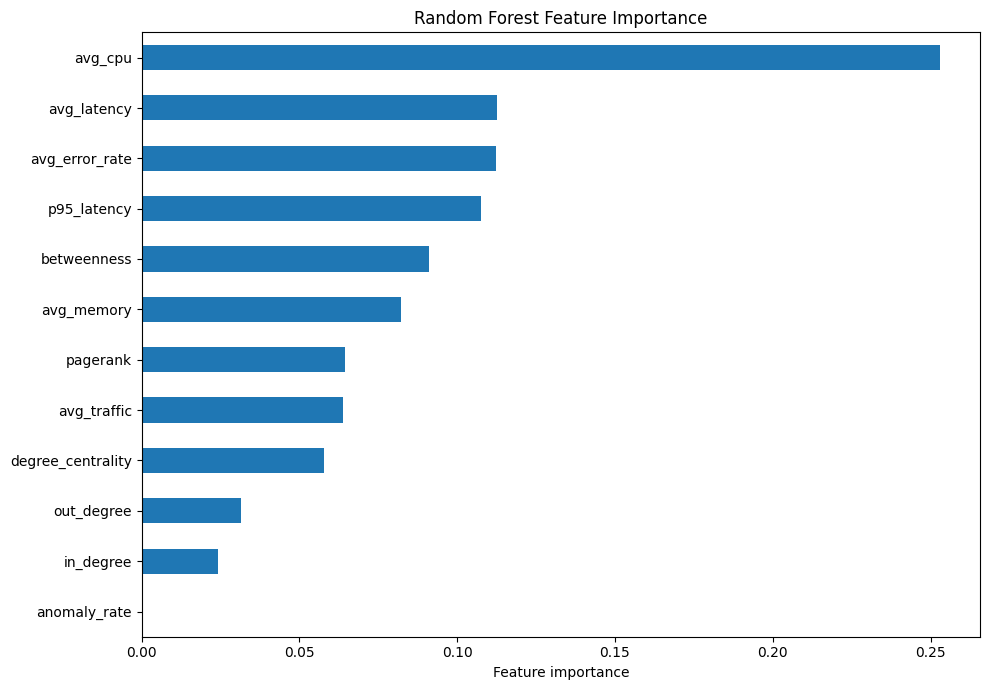

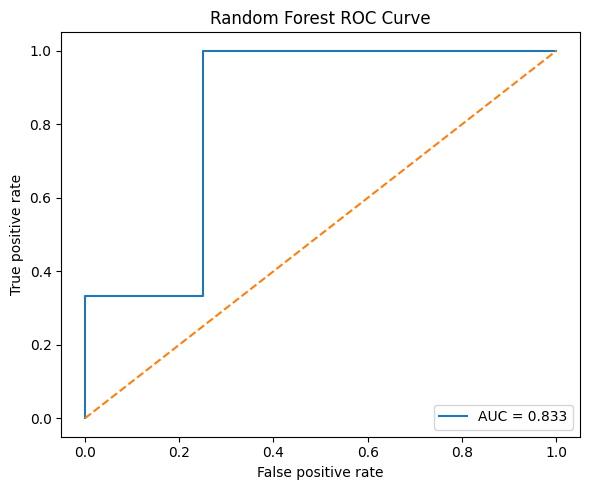

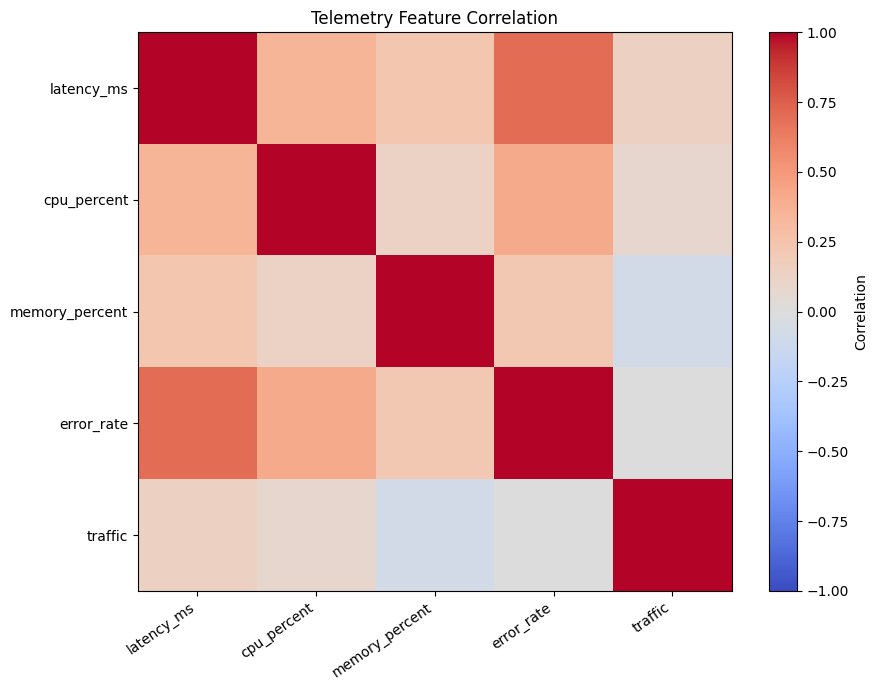


[8/10] Exporting results...

[9/10] Best simulated strategy...
Lowest average cascade size under these assumptions: isolation
Average failed services: 1.141

[10/10] COMPLETE
Output directory: /content/ORACLE_X_Complete_Results
Files generated:
 - 01_dependency_network.png
 - 02_service_risk.png
 - 03_cpu_timeline.png
 - 04_latency_timeline.png
 - 05_anomaly_distribution.png
 - 06_anomalies_by_service.png
 - 07_strategy_comparison.png
 - 08_cascade_distribution.png
 - 09_confusion_matrix.png
 - 10_feature_importance.png
 - 11_roc_curve.png
 - 12_telemetry_correlation.png
 - ORACLE_X_REPORT.txt
 - cascade_details.csv
 - cascade_simulations.csv
 - feature_importance.csv
 - service_dependencies.csv
 - service_ml_dataset.csv
 - service_risk_ranking.csv
 - service_risk_summary.csv
 - strategy_comparison.csv
 - synthetic_telemetry.csv
 - telemetry.csv
 - telemetry_engineered.csv

ORACLE-X execution finished successfully.
Note: labels, telemetry, risk scores and cascade probabilities are
syn

In [2]:

# ================================================================
# ORACLE-X SYSTEMS
# AI-Powered Failure Discovery & Network Resilience Intelligence
# Complete single-cell implementation
# ================================================================

import sys, subprocess, importlib.util, warnings, os
warnings.filterwarnings("ignore")

# 1. Install dependencies
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "networkx": "networkx",
    "sklearn": "scikit-learn"
}
for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

SEED = 42
rng = np.random.default_rng(SEED)
OUT = "ORACLE_X_Complete_Results"
os.makedirs(OUT, exist_ok=True)

print("=" * 70)
print("ORACLE-X | FAILURE DISCOVERY & NETWORK RESILIENCE ENGINE")
print("=" * 70)

# 2. Generate synthetic microservice architecture
services = [
    "API_Gateway", "Auth_Service", "User_Service", "Payment_Service",
    "Order_Service", "Inventory_Service", "Notification_Service",
    "Search_Service", "Recommendation_Service", "Analytics_Service",
    "Web_Frontend", "Mobile_Backend", "Cache_Service", "Queue_Service",
    "Primary_DB", "Replica_DB", "Object_Storage", "ML_Inference",
    "Monitoring_Service", "Logging_Service", "Config_Service",
    "Rate_Limiter"
]

edges = [
    ("Web_Frontend", "API_Gateway"),
    ("Mobile_Backend", "API_Gateway"),
    ("API_Gateway", "Auth_Service"),
    ("API_Gateway", "User_Service"),
    ("API_Gateway", "Order_Service"),
    ("API_Gateway", "Search_Service"),
    ("API_Gateway", "Rate_Limiter"),
    ("Order_Service", "Payment_Service"),
    ("Order_Service", "Inventory_Service"),
    ("Order_Service", "Queue_Service"),
    ("Payment_Service", "Primary_DB"),
    ("User_Service", "Primary_DB"),
    ("User_Service", "Cache_Service"),
    ("Inventory_Service", "Primary_DB"),
    ("Search_Service", "Cache_Service"),
    ("Search_Service", "ML_Inference"),
    ("Recommendation_Service", "ML_Inference"),
    ("Recommendation_Service", "Analytics_Service"),
    ("Analytics_Service", "Replica_DB"),
    ("Primary_DB", "Replica_DB"),
    ("Queue_Service", "Notification_Service"),
    ("Queue_Service", "Analytics_Service"),
    ("API_Gateway", "Monitoring_Service"),
    ("API_Gateway", "Logging_Service"),
    ("Auth_Service", "Config_Service"),
    ("Payment_Service", "Config_Service"),
    ("Object_Storage", "Analytics_Service"),
    ("ML_Inference", "Monitoring_Service"),
    ("Rate_Limiter", "Config_Service")
]

G = nx.DiGraph()
G.add_nodes_from(services)
G.add_edges_from(edges)

print(f"\nArchitecture: {G.number_of_nodes()} services, {G.number_of_edges()} dependencies")

# 3. Generate synthetic telemetry
records = []
n_steps = 500

for service in services:
    base_latency = rng.uniform(20, 180)
    base_cpu = rng.uniform(15, 65)
    base_memory = rng.uniform(25, 75)
    base_traffic = rng.uniform(50, 1000)

    incident_times = set(rng.choice(
        np.arange(30, n_steps - 10), size=12, replace=False
    ).tolist())

    for t in range(n_steps):
        incident = int(any(abs(t - x) <= 2 for x in incident_times))
        drift = max(0, t - 350) / 150

        cpu = np.clip(
            base_cpu + 8 * drift + rng.normal(0, 8) + incident * 24, 1, 100
        )
        memory = np.clip(
            base_memory + 5 * drift + rng.normal(0, 5) + incident * 12, 1, 100
        )
        latency = max(
            1, base_latency + rng.normal(0, 12) + cpu * 0.7 + incident * 130
        )
        error_rate = np.clip(
            rng.beta(1, 35) + incident * 0.22, 0, 1
        )
        traffic = max(
            1, base_traffic + rng.normal(0, base_traffic * 0.12)
        )

        records.append({
            "timestamp": t,
            "service": service,
            "latency_ms": latency,
            "cpu_percent": cpu,
            "memory_percent": memory,
            "error_rate": error_rate,
            "traffic": traffic,
            "incident_label": incident
        })

df = pd.DataFrame(records)
print("Telemetry shape:", df.shape)

# 4. Anomaly detection per service
feature_cols = [
    "latency_ms", "cpu_percent", "memory_percent",
    "error_rate", "traffic"
]
df["anomaly"] = 0
df["anomaly_score"] = 0.0

for service in services:
    mask = df["service"].eq(service)
    model = IsolationForest(
        n_estimators=120, contamination=0.06, random_state=SEED
    )
    model.fit(df.loc[mask, feature_cols])
    df.loc[mask, "anomaly"] = (
        model.predict(df.loc[mask, feature_cols]) == -1
    ).astype(int)
    df.loc[mask, "anomaly_score"] = -model.decision_function(
        df.loc[mask, feature_cols]
    )

print("Anomaly detection complete:", int(df["anomaly"].sum()), "flagged rows")

# 5. Network centrality and service risk scores
degree = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G, normalized=True)
pagerank = nx.pagerank(G, alpha=0.85)
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

agg = df.groupby("service").agg(
    avg_latency=("latency_ms", "mean"),
    p95_latency=("latency_ms", lambda x: x.quantile(0.95)),
    avg_cpu=("cpu_percent", "mean"),
    avg_memory=("memory_percent", "mean"),
    avg_error_rate=("error_rate", "mean"),
    avg_traffic=("traffic", "mean"),
    anomaly_rate=("anomaly", "mean"),
    incident_rate=("incident_label", "mean")
).reset_index()

agg["degree_centrality"] = agg["service"].map(degree)
agg["betweenness"] = agg["service"].map(betweenness)
agg["pagerank"] = agg["service"].map(pagerank)
agg["in_degree"] = agg["service"].map(in_degree)
agg["out_degree"] = agg["service"].map(out_degree)

def minmax(series):
    series = series.astype(float)
    span = series.max() - series.min()
    return (series - series.min()) / span if span > 0 else series * 0

agg["risk_score"] = (
    0.25 * minmax(agg["anomaly_rate"]) +
    0.20 * minmax(agg["avg_latency"]) +
    0.20 * minmax(agg["avg_error_rate"]) +
    0.15 * minmax(agg["avg_cpu"]) +
    0.12 * minmax(agg["betweenness"]) +
    0.08 * minmax(agg["pagerank"])
) * 100

agg["risk_level"] = pd.cut(
    agg["risk_score"],
    bins=[-0.01, 35, 65, 100.01],
    labels=["LOW", "MEDIUM", "HIGH"]
)

agg = agg.sort_values("risk_score", ascending=False).reset_index(drop=True)

print("\nTOP 10 SERVICE RISKS")
print(agg[["service", "risk_score", "risk_level", "anomaly_rate"]]
      .head(10).to_string(index=False))

# 6. Monte Carlo cascading failure simulation
print("\n[5/10] Simulating cascading failures...")

strategies = {
    "baseline": {"risk_multiplier": 1.00, "protection": 0.00},
    "isolation": {"risk_multiplier": 0.65, "protection": 0.45},
    "monitoring": {"risk_multiplier": 0.85, "protection": 0.20},
    "redundancy": {"risk_multiplier": 0.72, "protection": 0.35}
}

# Probability assumptions are illustrative, not learned from real incidents.
base_probability = {
    s: float(np.clip(
        0.06 + 0.24 * (agg.set_index("service").loc[s, "risk_score"] / 100),
        0.03, 0.32
    )) for s in services
}

n_simulations = 300
cascade_records = []

for strategy, params in strategies.items():
    for initial_service in services:
        for sim in range(n_simulations):
            failed = {initial_service}
            frontier = [initial_service]

            while frontier:
                current = frontier.pop()
                for neighbor in G.successors(current):
                    if neighbor in failed:
                        continue

                    p = base_probability[neighbor] * params["risk_multiplier"]

                    if strategy == "isolation" and neighbor == "Primary_DB":
                        p *= 1 - params["protection"]

                    if strategy == "redundancy" and neighbor in ["Primary_DB", "Replica_DB"]:
                        p *= 1 - params["protection"]

                    if rng.random() < np.clip(p, 0, 0.95):
                        failed.add(neighbor)
                        frontier.append(neighbor)

            cascade_records.append({
                "strategy": strategy,
                "initial_service": initial_service,
                "simulation": sim,
                "failed_services": len(failed),
                "cascade_fraction": len(failed) / len(services)
            })

cascade_df = pd.DataFrame(cascade_records)
strategy_summary = cascade_df.groupby("strategy").agg(
    mean_failed_services=("failed_services", "mean"),
    cascade_probability=("cascade_fraction", "mean"),
    maximum_failed_services=("failed_services", "max")
).reset_index()

baseline_mean = float(
    strategy_summary.loc[
        strategy_summary["strategy"] == "baseline", "mean_failed_services"
    ].iloc[0]
)
strategy_summary["change_vs_baseline_percent"] = (
    (strategy_summary["mean_failed_services"] - baseline_mean)
    / max(baseline_mean, 1e-9) * 100
)

print("\nSIMULATED STRATEGY COMPARISON")
print(strategy_summary.round(3).to_string(index=False))

# 7. Robust ML training: explicitly guarantee two target classes
print("\n[6/10] Training Random Forest on synthetic labels...")

# One row per service. Labels use risk-score ranking to ensure both classes.
# This is a demonstration label, not an independently verified failure outcome.
ml_df = agg.copy()
threshold = ml_df["risk_score"].median()
ml_df["target"] = (ml_df["risk_score"] >= threshold).astype(int)

# Defensive guarantee: split by rank if any unusual data produces one class.
if ml_df["target"].nunique() < 2:
    order = ml_df["risk_score"].rank(method="first")
    ml_df["target"] = (order > len(ml_df) // 2).astype(int)

ml_features = [
    "avg_latency", "p95_latency", "avg_cpu", "avg_memory",
    "avg_error_rate", "avg_traffic", "anomaly_rate",
    "degree_centrality", "betweenness", "pagerank",
    "in_degree", "out_degree"
]

X = ml_df[ml_features].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)
y = ml_df["target"].astype(int)

assert y.nunique() == 2, "Training target must contain two classes."
assert y.value_counts().min() >= 2, "Each class needs at least two samples."

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=SEED
)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 8. Visualizations
print("\n[7/10] Creating visualizations...")

# 1: Service dependency network
plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G, seed=SEED, k=0.8)
risk_map = agg.set_index("service")["risk_score"].to_dict()
node_colors = [risk_map[n] for n in G.nodes()]
nx.draw_networkx_edges(G, pos, alpha=0.25, arrows=True, arrowsize=12)
nodes = nx.draw_networkx_nodes(
    G, pos, node_size=850, node_color=node_colors,
    cmap=plt.cm.RdYlGn_r, edgecolors="black"
)
nx.draw_networkx_labels(G, pos, font_size=7)
plt.colorbar(nodes, label="Risk score")
plt.title("ORACLE-X: Microservice Dependency & Risk Network")
plt.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/01_dependency_network.png", dpi=160)
plt.show()

# 2: Risk ranking
plt.figure(figsize=(12, 7))
risk_plot = agg.sort_values("risk_score")
plt.barh(risk_plot["service"], risk_plot["risk_score"])
plt.xlabel("Risk score (0–100)")
plt.title("Service Failure Risk Ranking")
plt.tight_layout()
plt.savefig(f"{OUT}/02_service_risk.png", dpi=160)
plt.show()

# 3: CPU timeline for top-risk services
plt.figure(figsize=(13, 5))
top_services = agg.head(5)["service"].tolist()
for s in top_services:
    temp = df[df["service"] == s]
    plt.plot(temp["timestamp"], temp["cpu_percent"], label=s, linewidth=1)
plt.xlabel("Time step")
plt.ylabel("CPU (%)")
plt.title("CPU Telemetry: Five Highest-Risk Services")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/03_cpu_timeline.png", dpi=160)
plt.show()

# 4: Latency timeline
plt.figure(figsize=(13, 5))
for s in top_services:
    temp = df[df["service"] == s]
    plt.plot(temp["timestamp"], temp["latency_ms"], label=s, linewidth=1)
plt.xlabel("Time step")
plt.ylabel("Latency (ms)")
plt.title("Latency Telemetry: Five Highest-Risk Services")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/04_latency_timeline.png", dpi=160)
plt.show()

# 5: Anomaly score distribution
plt.figure(figsize=(9, 5))
plt.hist(df["anomaly_score"], bins=45)
plt.xlabel("Anomaly score (higher = more unusual)")
plt.ylabel("Telemetry records")
plt.title("Isolation Forest Anomaly Score Distribution")
plt.tight_layout()
plt.savefig(f"{OUT}/05_anomaly_distribution.png", dpi=160)
plt.show()

# 6: Anomalies by service
anom = df.groupby("service")["anomaly"].sum().sort_values()
plt.figure(figsize=(12, 7))
anom.plot(kind="barh")
plt.xlabel("Flagged records")
plt.title("Anomaly Counts by Microservice")
plt.tight_layout()
plt.savefig(f"{OUT}/06_anomalies_by_service.png", dpi=160)
plt.show()

# 7: Strategy comparison
plt.figure(figsize=(10, 5))
plot_summary = strategy_summary.sort_values("mean_failed_services")
plt.bar(plot_summary["strategy"], plot_summary["mean_failed_services"])
plt.ylabel("Average failed services per simulation")
plt.title("Resilience Strategy Comparison")
plt.tight_layout()
plt.savefig(f"{OUT}/07_strategy_comparison.png", dpi=160)
plt.show()

# 8: Cascade distribution
plt.figure(figsize=(11, 6))
for strategy in strategies:
    values = cascade_df.loc[
        cascade_df["strategy"] == strategy, "failed_services"
    ]
    plt.hist(values, bins=np.arange(0.5, len(services) + 1.5),
             alpha=0.45, label=strategy)
plt.xlabel("Number of failed services")
plt.ylabel("Simulation count")
plt.title("Monte Carlo Cascade Failure Distributions")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/08_cascade_distribution.png", dpi=160)
plt.show()

# 9: Confusion matrix
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    display_labels=["Lower risk", "Higher risk"]
).plot(cmap="Blues", values_format="d")
plt.title("Random Forest: Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUT}/09_confusion_matrix.png", dpi=160)
plt.show()

# 10: Feature importance
importance = pd.Series(
    clf.feature_importances_, index=ml_features
).sort_values()
plt.figure(figsize=(10, 7))
importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(f"{OUT}/10_feature_importance.png", dpi=160)
plt.show()

# 11: ROC curve (only when test set contains both classes)
if y_test.nunique() == 2:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("Random Forest ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT}/11_roc_curve.png", dpi=160)
    plt.show()
else:
    roc_auc = float("nan")
    print("ROC curve skipped: test set contains only one class.")

# 12: Telemetry correlation heatmap
plt.figure(figsize=(9, 7))
corr = df[feature_cols].corr()
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label="Correlation")
plt.title("Telemetry Feature Correlation")
plt.tight_layout()
plt.savefig(f"{OUT}/12_telemetry_correlation.png", dpi=160)
plt.show()

# 9. Export datasets and reports
print("\n[8/10] Exporting results...")

df.to_csv(f"{OUT}/synthetic_telemetry.csv", index=False)
agg.to_csv(f"{OUT}/service_risk_ranking.csv", index=False)
cascade_df.to_csv(f"{OUT}/cascade_simulations.csv", index=False)
strategy_summary.to_csv(f"{OUT}/strategy_comparison.csv", index=False)
ml_df.to_csv(f"{OUT}/service_ml_dataset.csv", index=False)

importance.sort_values(ascending=False).rename(
    "importance"
).to_csv(f"{OUT}/feature_importance.csv")

with open(f"{OUT}/ORACLE_X_REPORT.txt", "w", encoding="utf-8") as f:
    f.write("ORACLE-X SYSTEMS REPORT\n")
    f.write("=" * 50 + "\n\n")
    f.write("IMPORTANT: Synthetic demonstration, not production validation.\n\n")
    f.write(f"Services: {len(services)}\n")
    f.write(f"Dependencies: {len(edges)}\n")
    f.write(f"Telemetry rows: {len(df)}\n")
    f.write(f"Flagged anomalies: {int(df['anomaly'].sum())}\n")
    f.write(f"Random Forest accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    f.write(f"ROC AUC: {roc_auc:.4f}\n\n")
    f.write("TOP 10 SERVICE RISKS\n")
    f.write(agg[["service", "risk_score", "risk_level"]].head(10).to_string(index=False))
    f.write("\n\nSTRATEGY COMPARISON\n")
    f.write(strategy_summary.round(3).to_string(index=False))
    f.write("\n\nMODEL FEATURE IMPORTANCE\n")
    f.write(importance.sort_values(ascending=False).to_string())
    f.write("\n")

# 10. Final summary
print("\n[9/10] Best simulated strategy...")
best_strategy = strategy_summary.sort_values(
    "mean_failed_services"
).iloc[0]

print("Lowest average cascade size under these assumptions:",
      best_strategy["strategy"])
print("Average failed services:",
      round(best_strategy["mean_failed_services"], 3))

print("\n[10/10] COMPLETE")
print("=" * 70)
print("Output directory:", os.path.abspath(OUT))
print("Files generated:")
for name in sorted(os.listdir(OUT)):
    print(" -", name)

print("\nORACLE-X execution finished successfully.")
print("Note: labels, telemetry, risk scores and cascade probabilities are")
print("synthetic/illustrative. Validate on real incident data before deployment.")
